# Chess project - midterm
Jia Jain (S25CSEU0014), CSET-211 Statistical Machine Learning

Idea: predict who wins a chess game using only the first 10 moves, and separately group players by how they play (clustering). Data is from the Lichess open database.

## 1. imports

In [1]:
import os, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import chess, chess.pgn

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, silhouette_score)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
RANDOM_STATE = 42

## 2. settings
reading first 20000 games from one lichess month. after first run it is saved in raw_games.csv so next time it just loads the csv.

In [2]:
SOURCE = "stream"
LICHESS_URL = "https://database.lichess.org/standard/lichess_db_standard_rated_2013-01.pgn.zst"
N_GAMES = 20000
EARLY_PLIES = 20            # 10 moves each = 20 plies
CACHE_FILE = "../data/raw_games.csv"   # data folder is one level up from this notebook
MIN_GAMES_PER_PLAYER = 5    # only for clustering

## 3. loading data and making features
The feature code is now in `src/features.py` (same code is used later by the app, so features are made the same way).
Each game is replayed move by move (python-chess). For first 10 moves I count captures, find when castling happened and track material balance. These become the columns of the table.

In [3]:
import sys
sys.path.append("..")       # lets Python find the src folder (one level up)
from src.features import extract_game_features, game_iterator

if os.path.exists(CACHE_FILE):
    df = pd.read_csv(CACHE_FILE)
    print("Loaded cached table:", CACHE_FILE)
else:
    games = game_iterator(SOURCE, LICHESS_URL, N_GAMES)
    df = pd.DataFrame([extract_game_features(g, EARLY_PLIES) for g in games])
    df.to_csv(CACHE_FILE, index=False)
    print("Parsed and cached:", CACHE_FILE)
print("Games:", len(df))
df.head()

Loaded cached table: ../data/raw_games.csv
Games: 20000


,white,black,white_elo,black_elo,eco,time_control,result,white_castle_ply,black_castle_ply,white_captures_early,black_captures_early,material_balance_at_cutoff,material_swing_early,plies_recorded
0,BFG9k,mamalak,1639.0,1403.0,C00,600+8,1-0,NaN,NaN,2,2,-2,5,20
1,Desmond_Wilson,savinka59,1654.0,1919.0,D04,480+2,1-0,NaN,NaN,2,4,-6,9,20
2,Kozakmamay007,VanillaShamanilla,1643.0,1747.0,C50,420+17,1-0,NaN,NaN,2,1,3,4,20
3,Naitero_Nagasaki,800,1824.0,1973.0,B12,60+1,0-1,NaN,NaN,2,2,0,4,20
4,nichiren1967,Naitero_Nagasaki,1765.0,1815.0,C00,60+1,0-1,15.0,NaN,0,1,-1,1,20


## 4. cleaning the data

missing values: castling time is missing if the player never castled in 10 moves. that is useful info so I made a 0/1 flag and filled the gap with 21 instead of dropping.

In [4]:
print(df.isna().sum())

before = len(df)
df = df.dropna(subset=["white_elo", "black_elo", "result"])
df = df[df["result"].isin(["1-0", "0-1", "1/2-1/2"])]
print(f"Dropped {before - len(df)} unusable rows (missing rating or unfinished game)")

df["white_castled_early"] = df["white_castle_ply"].notna().astype(int)
df["black_castled_early"] = df["black_castle_ply"].notna().astype(int)
df["white_castle_ply"] = df["white_castle_ply"].fillna(EARLY_PLIES + 1)
df["black_castle_ply"] = df["black_castle_ply"].fillna(EARLY_PLIES + 1)

white                             0
black                             0
white_elo                        14
black_elo                        26
eco                               0
time_control                      0
result                            0
white_castle_ply              11501
black_castle_ply              12212
white_captures_early              0
black_captures_early              0
material_balance_at_cutoff        0
material_swing_early              0
plies_recorded                    0
dtype: int64
Dropped 40 unusable rows (missing rating or unfinished game)


duplicates

In [5]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Rows remaining:", len(df))

Duplicate rows: 2
Rows remaining: 19958


new columns + encoding (result to numbers, opening family one-hot)

In [6]:
df["elo_diff"] = df["white_elo"] - df["black_elo"]
df["avg_elo"] = (df["white_elo"] + df["black_elo"]) / 2

df["result_label"] = df["result"].map({"1-0": "white_win", "0-1": "black_win", "1/2-1/2": "draw"})
le = LabelEncoder()
df["result_encoded"] = le.fit_transform(df["result_label"])      # result -> numbers
print("Target encoding:", dict(zip(le.classes_, le.transform(le.classes_))))

df["eco_family"] = df["eco"].str[0]                               # opening family (A to E)
eco_dummies = pd.get_dummies(df["eco_family"], prefix="eco", drop_first=True)   # one-hot, drop_first to avoid dummy variable trap
df = pd.concat([df, eco_dummies], axis=1)
df[["eco", "eco_family", "result_label", "result_encoded"]].head()

Target encoding: {'black_win': np.int64(0), 'draw': np.int64(1), 'white_win': np.int64(2)}


,eco,eco_family,result_label,result_encoded
0,C00,C,white_win,2
1,D04,D,white_win,2
2,C50,C,white_win,2
3,B12,B,black_win,0
4,C00,C,black_win,0


outliers (IQR rule). they are real games (big rating gaps etc) so I kept them.

white_elo                      outliers: 269
black_elo                      outliers: 191
elo_diff                       outliers: 538
material_swing_early           outliers: 2064
material_balance_at_cutoff     outliers: 3580


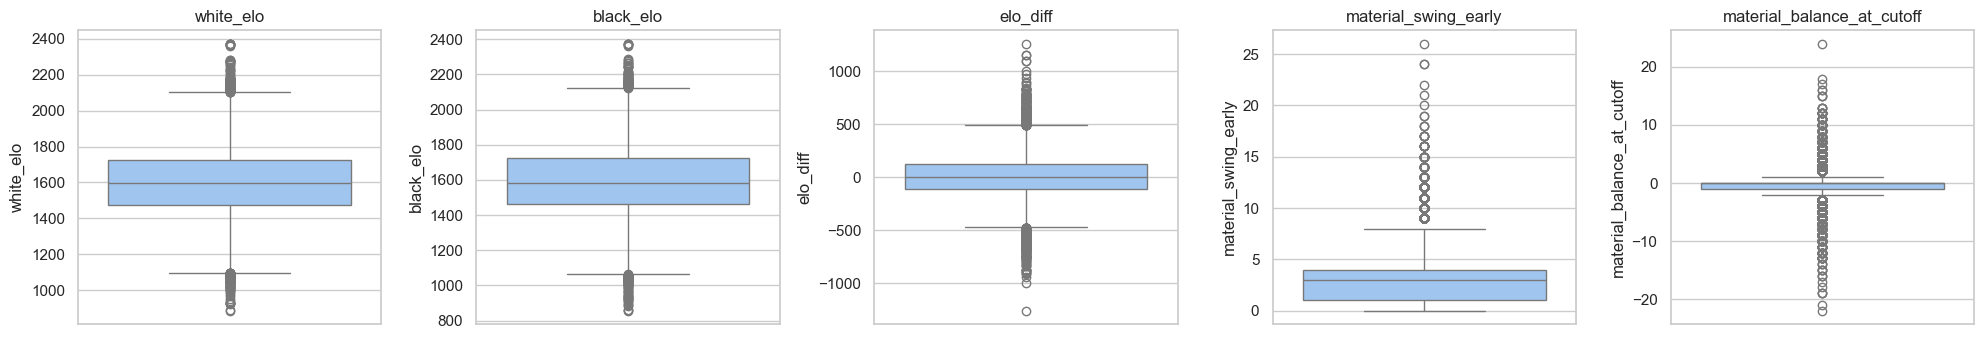

In [7]:
num_cols = ["white_elo", "black_elo", "elo_diff", "material_swing_early", "material_balance_at_cutoff"]
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    print(f"{c:30s} outliers: {n_out}")

fig, axes = plt.subplots(1, len(num_cols), figsize=(4 * len(num_cols), 3.5))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#93c5fd"); ax.set_title(c)
plt.tight_layout(); plt.show()

## 5. EDA

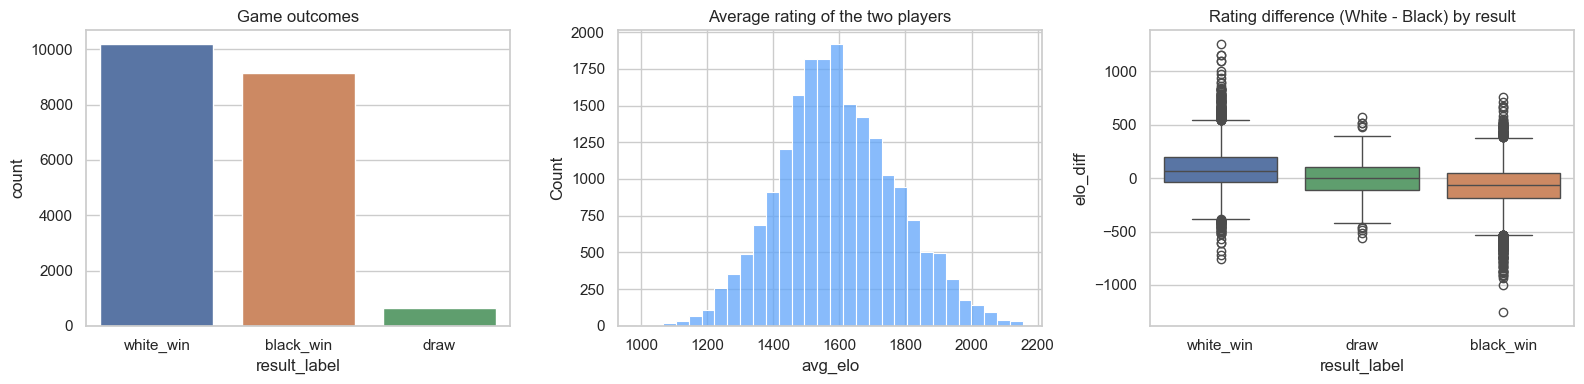

result_label
white_win    0.510
black_win    0.458
draw         0.032
Name: proportion, dtype: float64


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
order = df["result_label"].value_counts().index
sns.countplot(data=df, x="result_label", order=order, hue="result_label", legend=False, ax=axes[0]); axes[0].set_title("Game outcomes")
sns.histplot(df["avg_elo"], bins=30, ax=axes[1], color="#60a5fa"); axes[1].set_title("Average rating of the two players")
sns.boxplot(data=df, x="result_label", y="elo_diff", order=["white_win", "draw", "black_win"],
            hue="result_label", legend=False, ax=axes[2]); axes[2].set_title("Rating difference (White - Black) by result")
plt.tight_layout(); plt.show()
print(df["result_label"].value_counts(normalize=True).round(3))

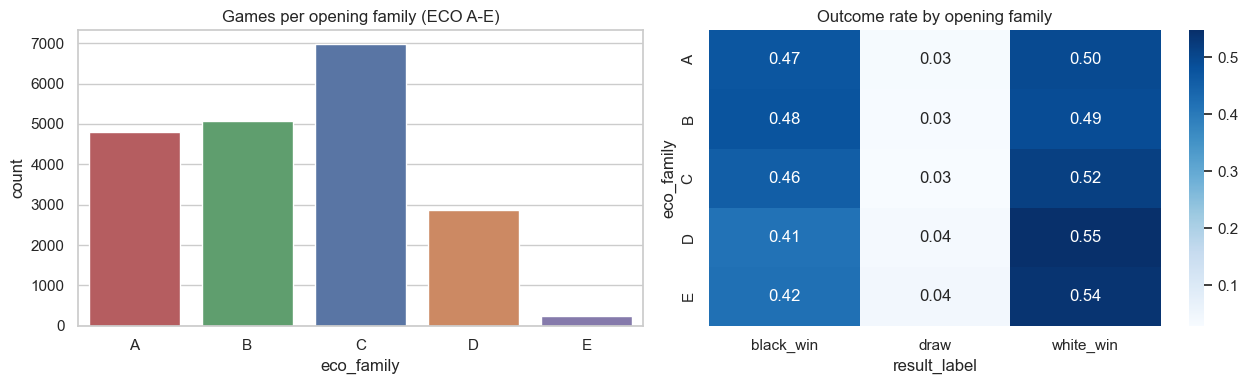

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="eco_family", order=sorted(df["eco_family"].dropna().unique()),
              hue="eco_family", legend=False, ax=axes[0]); axes[0].set_title("Games per opening family (ECO A-E)")
sns.heatmap(pd.crosstab(df["eco_family"], df["result_label"], normalize="index"), annot=True, fmt=".2f", cmap="Blues", ax=axes[1])
axes[1].set_title("Outcome rate by opening family")
plt.tight_layout(); plt.show()

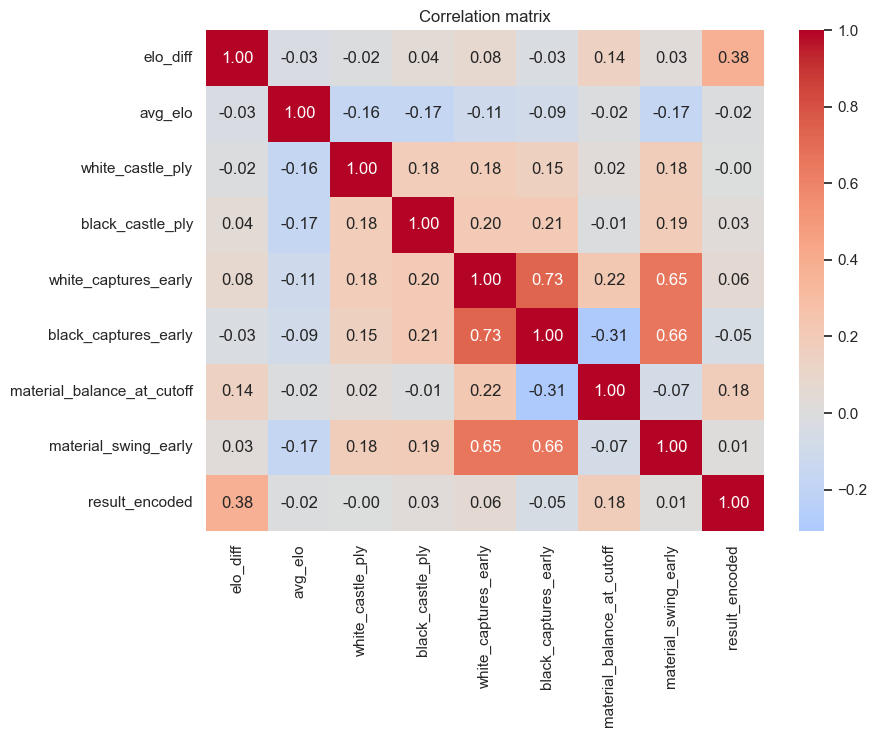

In [10]:
core = ["elo_diff", "avg_elo", "white_castle_ply", "black_castle_ply", "white_captures_early",
        "black_captures_early", "material_balance_at_cutoff", "material_swing_early", "result_encoded"]
plt.figure(figsize=(9, 6.5))
sns.heatmap(df[core].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

notes: white wins ~51%, black ~46%, draws only ~3% so classes are imbalanced. rating difference looks like the strongest signal.

## 6. predicting the result
using only first 10 moves + ratings. 80/20 split, scaling, then 4 models. accuracy alone is misleading because draws are rare so I also use macro F1.

In [11]:
feature_cols = ["elo_diff", "avg_elo", "white_castle_ply", "black_castle_ply", "white_captures_early",
                "black_captures_early", "material_balance_at_cutoff", "material_swing_early"] + list(eco_dummies.columns)
X, y = df[feature_cols].astype(float), df["result_encoded"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
scaler = StandardScaler().fit(X_train)                  # fit scaler on train only (no leakage)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print("Train:", X_train_s.shape, " Test:", X_test_s.shape)

Train: (15966, 12)  Test: (3992, 12)


In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "KNN (k=15)":          KNeighborsClassifier(n_neighbors=15),
    "SVM (RBF kernel)":    SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, fitted = [], {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    p, r, f1, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    cv_acc = cross_val_score(model, X_train_s, y_train, cv=cv, scoring="accuracy").mean()
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred), "Macro Precision": p,
                 "Macro Recall": r, "Macro F1": f1, "5-fold CV Acc": cv_acc})
    fitted[name] = model
results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Accuracy,Macro Precision,Macro Recall,Macro F1,5-fold CV Acc
Model,,,,,
Logistic Regression,0.527,0.457,0.438,0.417,0.537
KNN (k=15),0.601,0.400,0.413,0.406,0.618
SVM (RBF kernel),0.498,0.462,0.450,0.408,0.500
Random Forest,0.624,0.429,0.433,0.429,0.630


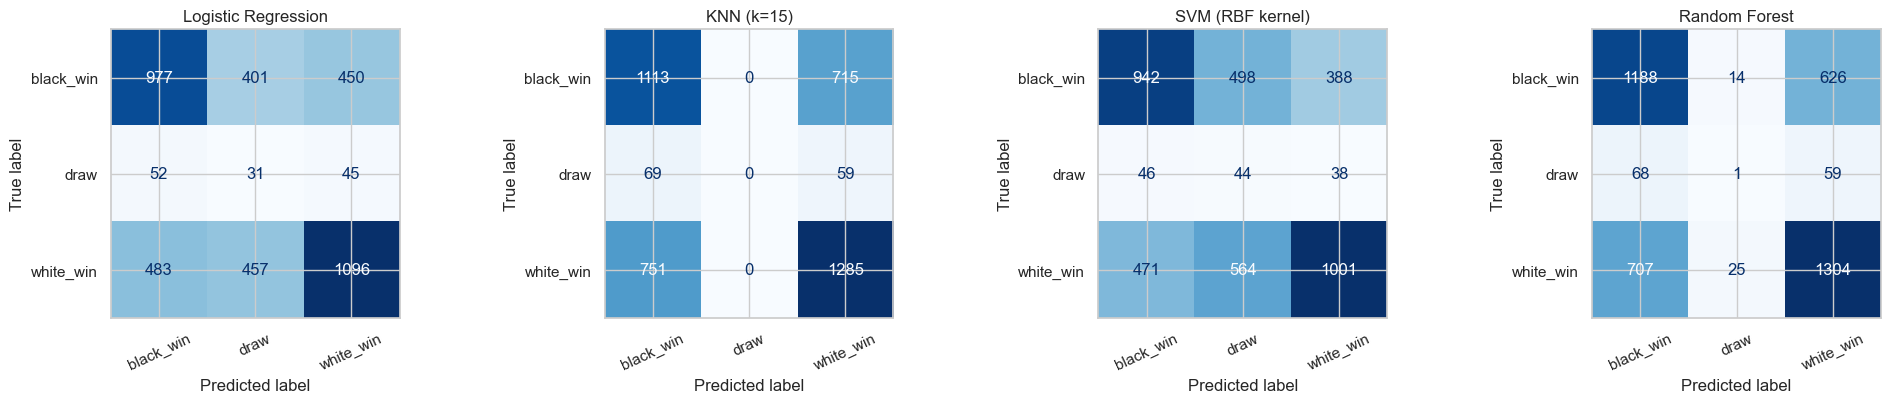

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for ax, (name, model) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test_s, y_test, display_labels=le.classes_, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

In [14]:
best = results["Macro F1"].idxmax()
print("Best model by macro F1:", best)
print(classification_report(y_test, fitted[best].predict(X_test_s), target_names=le.classes_, zero_division=0))

Best model by macro F1: Random Forest
              precision    recall  f1-score   support

   black_win       0.61      0.65      0.63      1828
        draw       0.03      0.01      0.01       128
   white_win       0.66      0.64      0.65      2036

    accuracy                           0.62      3992
   macro avg       0.43      0.43      0.43      3992
weighted avg       0.61      0.62      0.62      3992



which features matter + what if ratings are removed

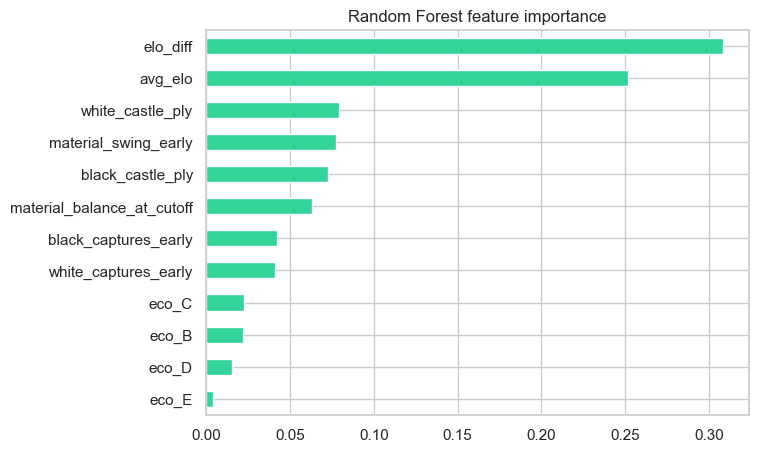

Accuracy with ratings   : 0.624
Accuracy without ratings: 0.427


In [15]:
imp = pd.Series(fitted["Random Forest"].feature_importances_, index=feature_cols).sort_values()
imp.plot(kind="barh", figsize=(7, 5), color="#34d399"); plt.title("Random Forest feature importance"); plt.show()

# what happens if we remove the ratings?
board_cols = [c for c in feature_cols if c not in ("elo_diff", "avg_elo")]
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(df[board_cols].astype(float), y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1).fit(Xb_tr, yb_tr)
print("Accuracy with ratings   :", round(results.loc["Random Forest", "Accuracy"], 3))
print("Accuracy without ratings:", round(rf.score(Xb_te, yb_te), 3))

## 7. clustering players
One row per player (all their games, both colours). Only style features are used, not results or ratings.

In [16]:
w = df[["white", "white_castle_ply", "white_castled_early", "white_captures_early", "material_swing_early", "eco"]].copy()
w.columns = ["player", "castle_ply", "castled_early", "captures_early", "material_swing", "eco"]
b = df[["black", "black_castle_ply", "black_castled_early", "black_captures_early", "material_swing_early", "eco"]].copy()
b.columns = w.columns
long = pd.concat([w, b])

players = long.groupby("player").agg(n_games=("eco", "size"),
                                      avg_castle_ply=("castle_ply", "mean"),
                                      castle_rate=("castled_early", "mean"),
                                      avg_captures=("captures_early", "mean"),
                                      avg_material_swing=("material_swing", "mean"),
                                      opening_variety=("eco", lambda s: s.head(5).nunique() / 5))
players = players[players["n_games"] >= MIN_GAMES_PER_PLAYER]
print("Players with >=", MIN_GAMES_PER_PLAYER, "games:", len(players))
players.describe().round(2)

Players with >= 5 games: 1200


,n_games,avg_castle_ply,castle_rate,avg_captures,avg_material_swing,opening_variety
count,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00
mean,32.06,18.51,0.39,1.64,3.46,0.78
std,41.51,2.00,0.25,0.42,1.14,0.22
min,5.00,9.67,0.00,0.25,0.57,0.20
25%,9.00,17.30,0.19,1.36,2.65,0.60
50%,18.00,18.88,0.38,1.63,3.35,0.80
75%,38.00,20.14,0.58,1.93,4.12,1.00
max,603.00,21.00,1.00,3.12,9.50,1.00


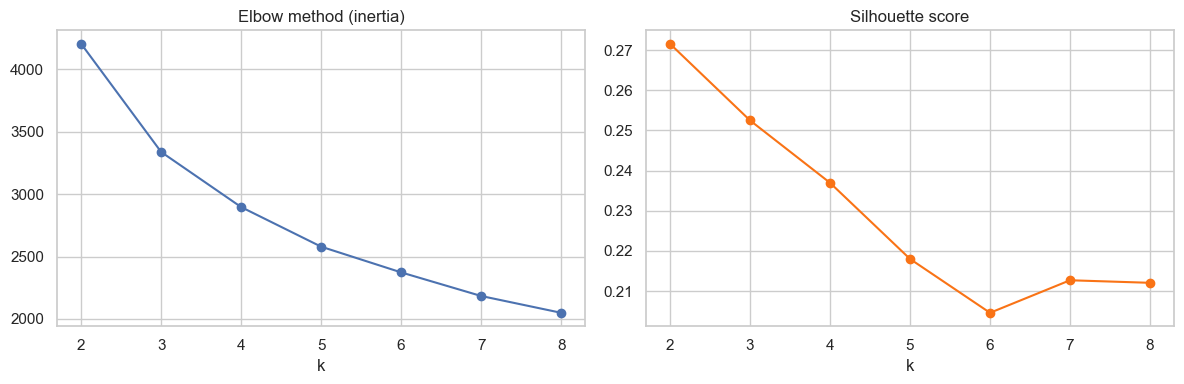

{2: np.float64(0.272), 3: np.float64(0.252), 4: np.float64(0.237), 5: np.float64(0.218), 6: np.float64(0.205), 7: np.float64(0.213), 8: np.float64(0.212)}


In [17]:
style_cols = ["avg_castle_ply", "castle_rate", "avg_captures", "avg_material_swing", "opening_variety"]
Xc = StandardScaler().fit_transform(players[style_cols])

ks = range(2, 9)
inertia = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc).inertia_ for k in ks]
sil = [silhouette_score(Xc, KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(Xc)) for k in ks]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertia, "o-"); axes[0].set_title("Elbow method (inertia)"); axes[0].set_xlabel("k")
axes[1].plot(list(ks), sil, "o-", color="#f97316"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()
print(dict(zip(ks, np.round(sil, 3))))

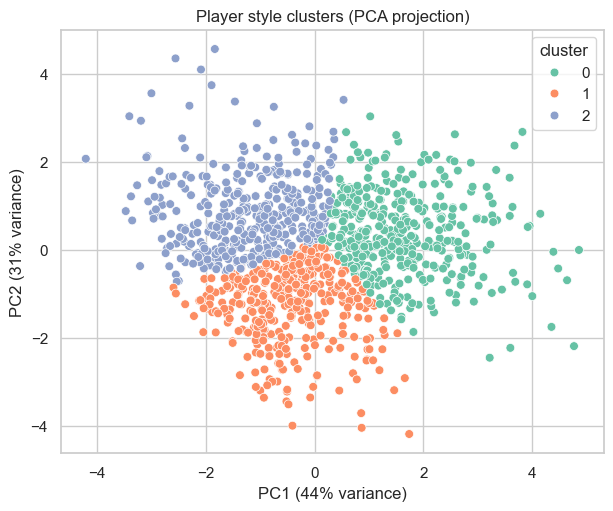

,avg_castle_ply,castle_rate,avg_captures,avg_material_swing,opening_variety,n_games,players
cluster,,,,,,,
0,16.40,0.65,1.49,2.83,0.81,36.44,411
1,19.91,0.21,1.41,3.00,0.66,34.17,385
2,19.32,0.29,2.02,4.52,0.86,25.59,404


In [18]:
K_CHOSEN = 3  # chosen from elbow + silhouette
km = KMeans(n_clusters=K_CHOSEN, n_init=10, random_state=RANDOM_STATE).fit(Xc)
players["cluster"] = km.labels_

pca = PCA(n_components=2, random_state=RANDOM_STATE)
pts = pca.fit_transform(Xc)
plt.figure(figsize=(7, 5.5))
sns.scatterplot(x=pts[:, 0], y=pts[:, 1], hue=players["cluster"], palette="Set2", s=40)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% variance)"); plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f}% variance)")
plt.title("Player style clusters (PCA projection)"); plt.show()

players.groupby("cluster")[style_cols + ["n_games"]].mean().round(2).assign(players=players["cluster"].value_counts().sort_index())

notes: silhouette is low (0.25 for k=3, best is 0.27 at k=2) so the clusters overlap. picked k=3 because k=2 is too simple and elbow bends most at 3. cluster 0 = early castlers, cluster 1 = king stays in centre / repeats openings, cluster 2 = tactical (more captures, bigger swings).

## 8. done / left
done: data loading, features, cleaning, EDA, 4 classifiers, k-means + PCA.

left: tune models (GridSearchCV), try hierarchical clustering and DBSCAN, bigger/newer dataset, streamlit demo, final report.

# Part 2 - final project (after the midterm)
The midterm cells above are unchanged. Below is what I added after the midterm:
new data (2025), more features, Stockfish, the final model, accuracy by cutoff, and clustering on 2025 data.

Slow steps (Stockfish on 600k positions, training on 200k games) were run as scripts in `src/`.
They saved their results in `results/` and the models in `models/`, so here I mostly **load** them.
Each section says which script made the numbers.

Rules I kept for every result:
- **train CV** = 5-fold cross-validation on the training games only (used to choose models)
- **test** = games the model never saw, used **once** at the end
- the **always White** baseline is shown next to every accuracy, plus **macro-F1**

In [19]:
import json, joblib
import matplotlib.patches as mpatches
from IPython.display import display

ROOT = ".."                                   # project folder (this notebook is in notebook/)
RES = ROOT + "/results/"
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9a9a"

## 9. fair before/after on the midterm games (2013)
Same 20,000 games as the midterm (first 20,000 games of Jan 2013 - checked identical to `raw_games.csv`),
same cleaning, same 80/20 split. Only the features and the model change.
- before = midterm Random Forest (balanced) with the 12 old features
- after = Logistic Regression with the new features (`src/features.py`, version 2), no class weights

In [20]:
from src.features import add_model_columns, RATING_COLS_V2, TIME_COLS_V2, BOARD_COLS_V2

g13 = pd.read_csv(ROOT + "/data/games_2013_01_all.csv.gz").head(20000)
g13 = g13.dropna(subset=["white_elo", "black_elo", "result"])
g13 = g13[g13["result"].isin(["1-0", "0-1", "1/2-1/2"])]
v1_cols = ["white", "black", "white_elo", "black_elo", "eco", "time_control", "result", "white_castle_ply",
           "black_castle_ply", "white_captures_early", "black_captures_early", "material_balance_at_cutoff",
           "material_swing_early", "plies_recorded"]
g13 = add_model_columns(g13.drop_duplicates(subset=v1_cols).reset_index(drop=True))
y13 = g13["result"].map({"0-1": 0, "1/2-1/2": 1, "1-0": 2}).values
tr, te = train_test_split(np.arange(len(g13)), test_size=0.2, random_state=RANDOM_STATE, stratify=y13)

old12 = ["elo_diff", "avg_elo", "white_castle_ply", "black_castle_ply", "white_captures_early", "black_captures_early",
         "material_balance_at_cutoff", "material_swing_early", "eco_B", "eco_C", "eco_D", "eco_E"]
new_cols = RATING_COLS_V2 + TIME_COLS_V2 + BOARD_COLS_V2
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
before = make_pipeline(StandardScaler(), RandomForestClassifier(200, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))
after = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=3000))   # a few 2013 values are missing -> train median

rows = [{"model": "always White (baseline)", "features": "-", "test_acc": (y13[te] == 2).mean(), "test_macroF1": np.nan}]
for name, m, cols in [("before: Random Forest balanced (midterm)", before, old12), ("after: Logistic Regression", after, new_cols)]:
    m.fit(g13.loc[tr, cols].astype(float), y13[tr])
    p = m.predict(g13.loc[te, cols].astype(float))
    rows.append({"model": name, "features": f"{len(cols)} features", "test_acc": accuracy_score(y13[te], p),
                 "test_macroF1": f1_score(y13[te], p, average="macro")})
ba = pd.DataFrame(rows).round(4)
ba.to_csv(RES + "before_after_2013.csv", index=False)
print(f"{len(g13)} games, train {len(tr)}, test {len(te)}")
ba

19958 games, train 15966, test 3992


,model,features,test_acc,test_macroF1
0,always White (baseline),-,0.5100,NaN
1,before: Random Forest balanced (midterm),12 features,0.6245,0.4289
2,after: Logistic Regression,52 features,0.6621,0.4471


notes: on the same games the test accuracy goes from about 62.4% to 66.2% (always White = 51%).
most of the gain came from dropping `class_weight="balanced"` (it made the model guess draws/Black too often)
and from the new features (rating expected score, time control, development, mobility, piece counts).

## 10. new data: Lichess blitz games from 2025
Source: Hugging Face `Lichess/standard-chess-games` (the official Lichess database as parquet files;
lichess.org itself is blocked on my network). One file of 1 January 2025.
Built with `src/build_dataset.py`. Rules:
- blitz only (Lichess rule: base + 40 x increment between 180 and 479 seconds)
- both ratings present, valid result, no BOT accounts
- the game must still be going **after** move 10 (otherwise the result is already known at the cutoff)

A second file (same day, later hours, no shared games) is kept **untouched** as the final test file.

In [21]:
DATA_2025 = ROOT + "/data/games_2025_01_blitz.csv.gz"
if not os.path.exists(DATA_2025):        # GitHub copy only has a small sample of the big file
    DATA_2025 = ROOT + "/data/sample/games_2025_01_blitz_sample.csv.gz"
    print("NOTE: full 2025 file not found, using the small sample - numbers below will differ a bit")
g25 = pd.read_csv(DATA_2025)
print("file:", DATA_2025, "| games:", len(g25))
print("results:", g25["result"].value_counts(normalize=True).round(3).to_dict())
gap13 = (g13["white_elo"] - g13["black_elo"]).abs()
gap25 = (g25["white_elo"] - g25["black_elo"]).abs()
pd.DataFrame({"2013 midterm": [gap13.median(), (gap13 > 200).mean()], "2025 blitz": [gap25.median(), (gap25 > 200).mean()]},
             index=["median rating gap", "share of games with gap > 200"]).round(3)

file: ../data/games_2025_01_blitz.csv.gz | games: 623722
results: {'1-0': 0.496, '0-1': 0.461, '1/2-1/2': 0.043}


,2013 midterm,2025 blitz
median rating gap,121.000,29.000
share of games with gap > 200,0.286,0.046


notes: in 2025 Lichess pairs players of almost the same rating (median gap about 29 points, it was 121 in 2013),
so ratings alone say much less about the winner. That is why accuracy on 2025 is lower than on 2013 -
the task is harder, the model is not worse. draws are about 4%.

## 11. features at the cutoff and the leakage rules
Everything is measured at the cutoff (move 10 = ply 20 for the main model), in `src/features.py`:
- ratings: White, Black, difference, average, Elo expected score
- time control: base time and increment; clocks: time left for each side at the cutoff
- board: material balance and swing, captures, checks, castling (when/which side), knights/bishops developed,
  queen moved, centre pawns, mobility (legal moves), hanging pieces, king pawn shield, piece counts, opening (ECO)
- Stockfish: evaluation of the board at the cutoff (depth 10) - see section 13

Never used (they come from after the cutoff or after the game): Termination, RatingDiff, `[%eval]` comments,
game length, anything after the cutoff move. Player history may only use games that finished **before** this game started.

Check below: I cut a real game after move 10 (later moves deleted, result hidden) and make the features again.

In [22]:
from src.features import extract_game_features_v2

full_game = chess.pgn.read_game(open(ROOT + "/data/sample_pgn/one_game.pgn"))
cut_game = chess.pgn.Game()
cut_game.headers.update(full_game.headers)
cut_game.headers["Result"] = "*"                 # result hidden
node = cut_game
for i, n in enumerate(full_game.mainline()):
    if i >= 20:                                  # keep only the first 20 plies (10 moves each)
        break
    node = node.add_variation(n.move)
    node.comment = n.comment                     # keeps the clock times of those moves

a = extract_game_features_v2(full_game, early_plies=20)
b = extract_game_features_v2(cut_game, early_plies=20)
diff = {k: (a[k], b[k]) for k in a if str(a[k]) != str(b[k])}
print("game length:", len(list(full_game.mainline_moves())), "plies | features compared:", len(a))
print("different values:", diff)

game length: 88 plies | features compared: 52
different values: {'result': ('0-1', '*'), 'game_continues': (1, 0)}


notes: only `result` and `game_continues` differ, and neither is a model input (result is the label,
game_continues is only used to filter games). so the features cannot see the future.
the same check on 1,913 real games gave the same answer (`PROJECT_CONTEXT.md`).

## 12. choosing the model (train CV only)
Script: `src/train_final_models.py`. 200,000 training games (2025), 5-fold cross-validation.
The test file was not used here.

,model,cv_acc_mean,cv_acc_std,cv_macroF1_mean,cv_always_white,n_train,secs
0,Soft voting (LR+LDA+HGB),0.5793,0.0021,0.3930,0.4959,200000,23
1,HistGradientBoosting,0.5790,0.0025,0.3928,0.4959,200000,8
2,Logistic Regression,0.5780,0.0016,0.3923,0.4959,200000,9
3,LDA,0.5772,0.0019,0.3916,0.4959,200000,7


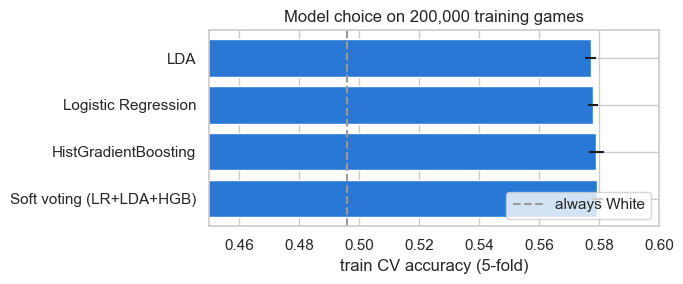

tuning (RandomizedSearchCV, train CV) - best 3:


,params,mean_test_score,std_test_score,rank_test_score
0,{'hgb__learning_rate': np.float64(0.0305156169...,0.58003,0.001982,1
1,{'hgb__learning_rate': np.float64(0.0233010322...,0.57996,0.002296,2
2,{'hgb__learning_rate': np.float64(0.0255617999...,0.57973,0.002301,3


In [23]:
cv = pd.read_csv(RES + "final_model_cv.csv")
display(cv)
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(cv["model"], cv["cv_acc_mean"], xerr=cv["cv_acc_std"], color=BLUE)
ax.axvline(cv["cv_always_white"].iloc[0], color=GREY, ls="--", label="always White")
ax.set_xlim(0.45, 0.6); ax.set_xlabel("train CV accuracy (5-fold)"); ax.legend(loc="lower right")
ax.set_title("Model choice on 200,000 training games"); plt.tight_layout(); plt.show()
print("tuning (RandomizedSearchCV, train CV) - best 3:")
pd.read_csv(RES + "final_model_tuning.csv").head(3)

notes: all models are within about 0.2 points (less than one CV standard deviation), so it is almost a tie.
soft voting (averages the probabilities of the models) was a little better, and tuning picked
weights [1, 0, 1] = Logistic Regression + HistGradientBoosting (LDA gets weight 0). tuning added only +0.07 points.

## 13. Stockfish and player history (two extra feature ideas)
- **Stockfish** (`src/stockfish_experiment.py`): the chess engine looks at the board at the cutoff (depth 10)
  and says who stands better (in pawns) and the expected score. It never sees later moves.
- **Player history** (`src/player_history.py`, `src/history_experiment.py`): win rate and score of each player
  in their earlier games, using only games that surely finished before this game started.

In [24]:
print("Stockfish (train CV, 200,000 games):")
display(pd.read_csv(RES + "stockfish_cv.csv"))
print("Player history (train CV, 200,000 games):")
display(pd.read_csv(RES + "history_cv.csv"))
print("History leakage check (numbers recomputed by brute force):")
pd.read_csv(RES + "history_leakage_check.csv")

Stockfish (train CV, 200,000 games):


,features,model,n_train_games,cv_acc_mean,cv_acc_std,cv_macroF1_mean,cv_always_white
0,without Stockfish,Logistic Regression,200000,0.5602,0.0016,0.3785,0.4959
1,without Stockfish,HistGradientBoosting,200000,0.5602,0.0011,0.3789,0.4959
2,with Stockfish,Logistic Regression,200000,0.5780,0.0016,0.3923,0.4959
3,with Stockfish,HistGradientBoosting,200000,0.5790,0.0025,0.3928,0.4959
4,ratings + Stockfish only,Logistic Regression,200000,0.5700,0.0024,0.3867,0.4959
5,ratings + Stockfish only,HistGradientBoosting,200000,0.5701,0.0021,0.3864,0.4959


Player history (train CV, 200,000 games):


,features,model,n_train_games,cv_acc_mean,cv_acc_std,cv_macroF1_mean,cv_always_white
0,base,Logistic Regression,200000,0.5601,0.0015,0.3785,0.4959
1,base,HistGradientBoosting,200000,0.5602,0.0011,0.3789,0.4959
2,base + history,Logistic Regression,200000,0.5599,0.0014,0.3784,0.4959
3,base + history,HistGradientBoosting,200000,0.5595,0.0015,0.3784,0.4959
4,base + Stockfish,Logistic Regression,200000,0.5780,0.0017,0.3923,0.4959
5,base + Stockfish,HistGradientBoosting,200000,0.5790,0.0025,0.3928,0.4959
6,base + Stockfish + history,Logistic Regression,200000,0.5779,0.0020,0.3923,0.4959
7,base + Stockfish + history,HistGradientBoosting,200000,0.5782,0.0024,0.3923,0.4959


History leakage check (numbers recomputed by brute force):


,pairs_checked,numbers_checked,mismatches,current_game_counted,counted_game_not_finished_before_start
0,4000,20000,0,0,0


notes: Stockfish adds about +1.8 points (0.560 -> 0.578), much more than the CV standard deviation (0.002), so I kept it.
player history gives no gain (differences below 0.001), probably because the data is only one day, so most players
have only a few earlier games, and the rating already sums up skill. so history was dropped.

## 14. final model - tested once on the untouched file
Soft voting (Logistic Regression + HistGradientBoosting), features = base + Stockfish, trained on 200,000 games.
Test = 200,000 random games from the untouched second file, Stockfish run on them, used **once**.

features: 59 | classes: ['black_win', 'draw', 'white_win']


,model,n_train,n_test,train_cv_acc,test_acc,test_macroF1,test_acc_always_white,predicted_draws
0,Soft voting (LR+LDA+HGB),200000,200000,0.58,0.5809,0.3945,0.4964,0


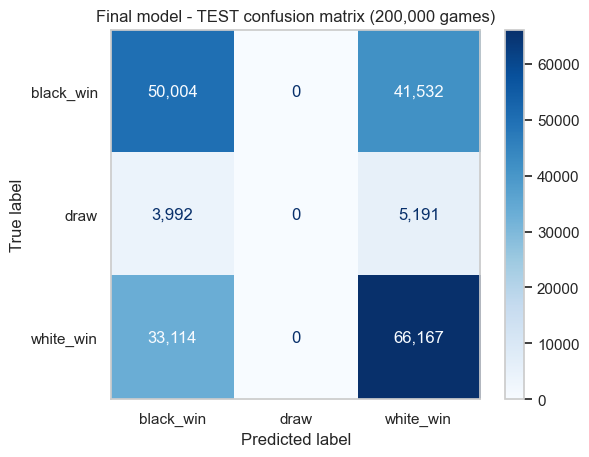

In [25]:
final = joblib.load(ROOT + "/models/model_move10.joblib")
print("features:", len(final["features"]), "| classes:", final["labels"])
test = pd.read_csv(RES + "final_model_test.csv")
display(test[["model", "n_train", "n_test", "train_cv_acc", "test_acc", "test_macroF1", "test_acc_always_white", "predicted_draws"]])

conf = pd.read_csv(RES + "final_model_confusion.csv", index_col=0)
ConfusionMatrixDisplay(conf.values, display_labels=["black_win", "draw", "white_win"]).plot(cmap="Blues", values_format=",")
plt.grid(False); plt.title("Final model - TEST confusion matrix (200,000 games)"); plt.show()

notes: test accuracy 58.1% vs 49.6% for always White, macro-F1 0.39. test is about the same as train CV (58.0%),
so the model does not overfit. **limitation: the model never predicts a draw** (draws are only 4% and look like
normal games after 10 moves), so the draw column of predictions is empty.

In [26]:
# the saved model on one real game (same code as the app)
from src.predict import load_models, read_games, predict_all, stockfish_engine
models = load_models()
engine = stockfish_engine()          # None if Stockfish is not installed -> model without Stockfish is used
try:
    demo = predict_all(read_games(open(ROOT + "/data/sample_pgn/one_game.pgn").read()), models, engine)
finally:
    if engine is not None:
        engine.quit()
demo[["white", "black", "white_elo", "black_elo", "result", "cutoff_move", "used_stockfish", "stockfish_pawns",
      "p_white", "p_draw", "p_black"]].round(3)

,white,black,white_elo,black_elo,result,cutoff_move,used_stockfish,stockfish_pawns,p_white,p_draw,p_black
0,gata28,julioPM,1558,1554,0-1,30,True,4.86,0.835,0.033,0.132


## 15. how sure is the model, and does the rating gap matter? (test)

,model_at_least_sure,n_test_games,share_of_test,test_acc,test_acc_always_white_same_games
0,all games,200000,1.0000,0.5809,0.4964
1,>= 60%,61721,0.3086,0.6980,0.5269
2,>= 70%,25564,0.1278,0.7853,0.5506
3,>= 80%,8362,0.0418,0.8795,0.5814


,rating_gap,n_test_games,share_of_test,test_acc_always_white,test_acc_model,test_macroF1_model
0,0-50,131615,0.6581,0.4962,0.5604,0.3798
1,50-100,38721,0.1936,0.4974,0.5764,0.3921
2,100-200,18496,0.0925,0.4964,0.6240,0.4259
3,200+,11168,0.0558,0.4961,0.7667,0.5208


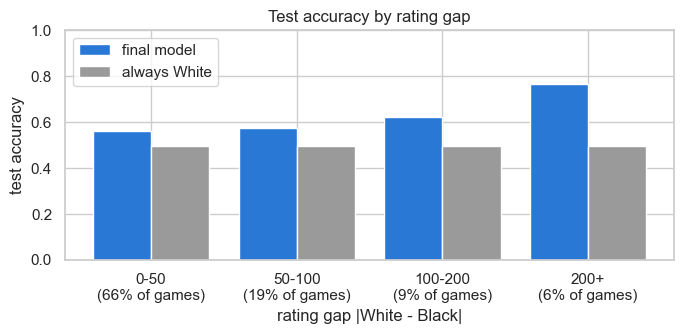

In [27]:
display(pd.read_csv(RES + "confidence_bands.csv"))
gap = pd.read_csv(RES + "accuracy_by_rating_gap.csv")
display(gap)
x = np.arange(len(gap))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(x - 0.2, gap["test_acc_model"], 0.4, color=BLUE, label="final model")
ax.bar(x + 0.2, gap["test_acc_always_white"], 0.4, color=GREY, label="always White")
ax.set_xticks(x, gap["rating_gap"] + "\n(" + (gap["share_of_test"] * 100).round(0).astype(int).astype(str) + "% of games)")
ax.set_ylim(0, 1); ax.set_ylabel("test accuracy"); ax.set_xlabel("rating gap |White - Black|")
ax.set_title("Test accuracy by rating gap"); ax.legend(); plt.tight_layout(); plt.show()

notes: when the model is at least 80% sure (4% of games) it is right 88% of the time, so the probabilities are useful.
with a big rating gap (200+) accuracy is 77%, but 66% of 2025 games have a gap under 50, where it is 56%.

## 16. accuracy by cutoff move (10, 15, 20, 25, 30 moves)
Script: `src/cutoff_experiment.py` (200,000 random games, only games still running after the cutoff, HGB, test split)
and `src/train_final_models.py` (one final model per cutoff, train CV).
The **same games** row uses only games that last past move 30, so the group of games is the same at every cutoff.

,games,cutoff_move,cutoff_ply,n_games,n_train,n_test,test_acc_always_white,test_acc_ratings_logreg,test_macroF1_ratings_logreg,test_acc_hgb_all,test_macroF1_hgb_all
0,still running after cutoff,10,20,191561,153248,38313,0.4957,0.5285,0.3486,0.5612,0.3805
1,same games (running after move 30),10,20,109091,87272,21819,0.4754,0.5120,0.3482,0.5416,0.3735
2,still running after cutoff,15,30,180171,144136,36035,0.4930,0.5243,0.3474,0.5978,0.4074
3,same games (running after move 30),15,30,109091,87272,21819,0.4754,0.5120,0.3482,0.5679,0.3920
4,still running after cutoff,20,40,161953,129562,32391,0.4885,0.5197,0.3476,0.6398,0.4379
5,same games (running after move 30),20,40,109091,87272,21819,0.4754,0.5120,0.3482,0.6031,0.4170
6,still running after cutoff,25,50,137478,109982,27496,0.4835,0.5194,0.3498,0.6686,0.4601
7,same games (running after move 30),25,50,109091,87272,21819,0.4754,0.5120,0.3482,0.6454,0.4464
8,still running after cutoff,30,60,109091,87272,21819,0.4754,0.5120,0.3482,0.6989,0.4854
9,same games (running after move 30),30,60,109091,87272,21819,0.4754,0.5120,0.3482,0.6989,0.4854


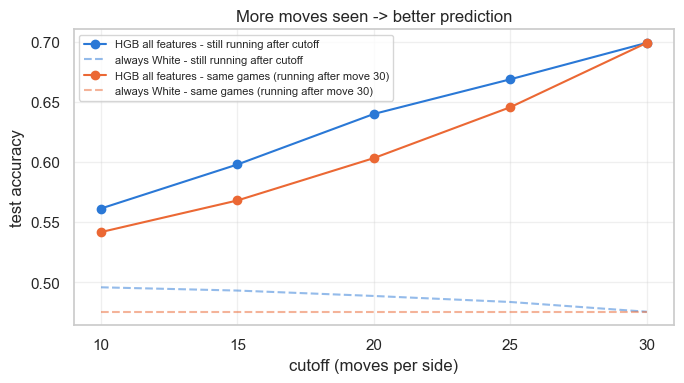

final models per cutoff (with Stockfish):


,cutoff_move,n_train,cv_acc_mean,cv_always_white,test_acc_part1,test_acc_always_white_part1,cv_acc_std,cv_macroF1_mean
0,10,200000,0.5800,0.4959,0.5809,0.4964,NaN,NaN
1,15,100000,0.6250,0.4948,NaN,NaN,0.0029,0.4255
2,20,100000,0.6639,0.4914,NaN,NaN,0.0031,0.4533
3,25,100000,0.6995,0.4852,NaN,NaN,0.0049,0.4797
4,30,100000,0.7190,0.4781,NaN,NaN,0.0028,0.4966


In [28]:
cut = pd.read_csv(RES + "accuracy_by_cutoff.csv")
display(cut)
fig, ax = plt.subplots(figsize=(7, 4))
for (grp, d), col in zip(cut.groupby("games", sort=False), [BLUE, ORANGE]):
    ax.plot(d["cutoff_move"], d["test_acc_hgb_all"], "o-", color=col, label=f"HGB all features - {grp}")
    ax.plot(d["cutoff_move"], d["test_acc_always_white"], "--", color=col, alpha=.5, label=f"always White - {grp}")
ax.set_xticks([10, 15, 20, 25, 30]); ax.set_xlabel("cutoff (moves per side)"); ax.set_ylabel("test accuracy"); ax.legend(fontsize=8)
ax.set_title("More moves seen -> better prediction"); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
print("final models per cutoff (with Stockfish):")
pd.read_csv(RES + "models_by_cutoff.csv")

notes: accuracy rises from 56% at move 10 to 70% at move 30. the "same games" line rises too, so the rise is real
and not only because short games drop out. the final per-cutoff models (with Stockfish) reach 0.580 / 0.625 / 0.664 /
0.700 / 0.719 train CV. the app uses the latest cutoff each game has reached.

## 17. decisive games only (White win vs Black win)
Draws are rare and never predicted, so I also trained a 2-class model on games that did not end in a draw.

In [29]:
pd.read_csv(RES + "decisive_only.csv")

,task,model,n_train,train_cv_acc,train_cv_std,n_test,test_acc,test_macroF1,test_acc_always_white
0,decisive only (White win vs Black win),Soft voting (LR+LDA+HGB),191354,0.6056,0.0026,190817,0.6079,0.6049,0.5203


notes: on decisive test games accuracy is 60.8% vs 52.0% for always White (+8.8 points).

## 18. clustering players on the 2025 data
Script: `src/clustering.py`, shared code in `src/style.py` (the app uses the same code).
One row per player with at least 5 games, averages over their games (first 10 moves only, both colours).
No ratings, no results. Features: castling move and castling rate, captures, material swing,
knights/bishops developed, mobility, opening variety (different ECO codes in the first 5 games / 5).

players with >= 5 games: 83870


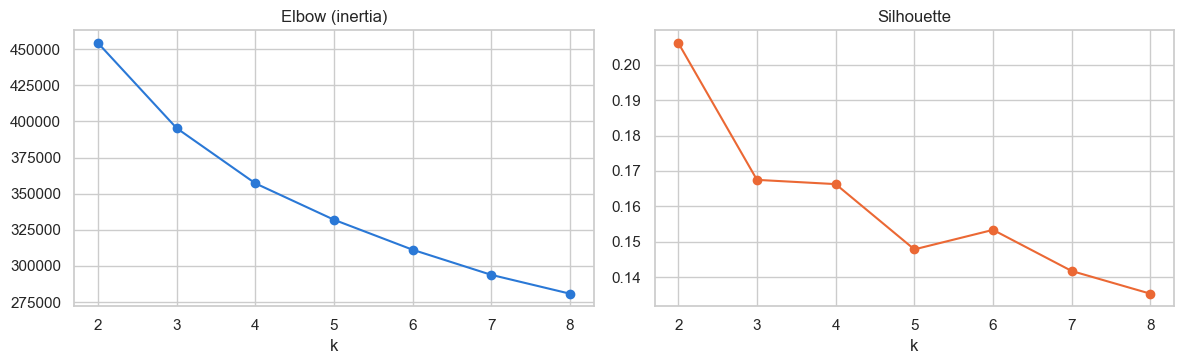

,k,inertia,silhouette,smallest_group_share
0,2,454218.1,0.2061,0.4677
1,3,395319.6,0.1675,0.2555
2,4,357157.9,0.1663,0.1275
3,5,331970.3,0.1479,0.1142
4,6,311219.7,0.1534,0.0809
5,7,293853.9,0.1418,0.0762
6,8,280824.7,0.1354,0.0548


In [30]:
from src.style import player_table, STYLE_COLS
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

players25 = player_table(g25, min_games=5)
style = joblib.load(ROOT + "/models/style_kmeans.joblib")
X25 = style["scaler"].transform(players25[STYLE_COLS])
print("players with >= 5 games:", len(players25))

sc = pd.read_csv(RES + "clustering_kmeans_scores.csv")          # k = 2..8 on all 83,870 players
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(sc["k"], sc["inertia"], "o-", color=BLUE); axes[0].set_title("Elbow (inertia)"); axes[0].set_xlabel("k")
axes[1].plot(sc["k"], sc["silhouette"], "o-", color=ORANGE); axes[1].set_title("Silhouette"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()
sc

notes: silhouette is low for every k (0.21 at k=2, 0.17 at k=3 and k=4), so player styles overlap a lot.
I chose **k = 3**: the elbow bends most at 3, k=3 and k=4 have the same silhouette, k=2 is too simple, and the midterm also used 3.

,players,avg_castle_ply,castle_rate,avg_captures,avg_material_swing,avg_minors_developed,avg_mobility,opening_variety,n_games
name,,,,,,,,,
Developer,31920,18.97,0.38,1.48,2.71,3.21,38.00,0.87,11.86
Early castler,30520,15.61,0.75,1.37,2.54,3.16,35.55,0.88,11.77
Tactical,21430,19.33,0.29,2.05,4.36,2.74,34.66,0.83,10.22


0 Developer: Brings knights and bishops out and keeps many moves available; often leaves the king in the centre for the first 10 moves. Few early captures.
1 Early castler: Puts the king safe early: castles in most games, and sooner than others. Quiet openings with the fewest captures and smallest material swings.
2 Tactical: Sharp, tactical starts: the most captures and the biggest material swings in the first 10 moves, fewer pieces developed, and rarely castles early.


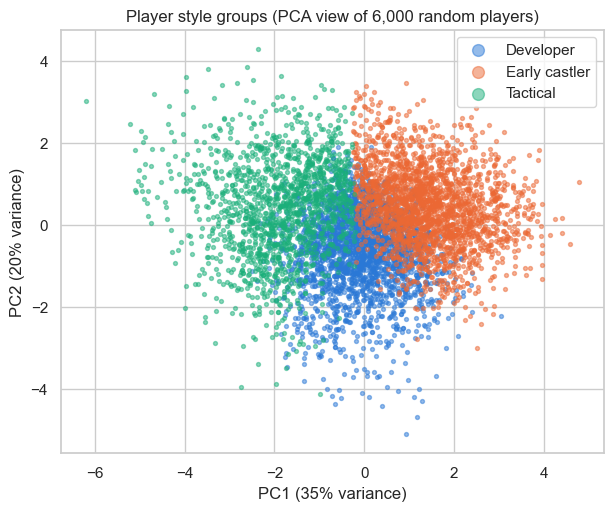

In [31]:
players25["group"] = style["kmeans"].predict(X25)
players25["name"] = players25["group"].map(style["names"])
prof = players25.groupby("name")[STYLE_COLS + ["n_games"]].mean().round(2)
prof.insert(0, "players", players25["name"].value_counts())
display(prof)
for g, n in style["names"].items():
    print(f"{g} {n}: {style['meanings'][g]}")

pca25 = PCA(n_components=2, random_state=RANDOM_STATE).fit(X25)
idx = np.random.RandomState(RANDOM_STATE).choice(len(X25), size=min(6000, len(X25)), replace=False)
pts = pca25.transform(X25[idx])
plt.figure(figsize=(7, 5.5))
for g, col in zip(range(3), [BLUE, ORANGE, GREEN]):
    m = players25["group"].values[idx] == g
    plt.scatter(pts[m, 0], pts[m, 1], s=8, alpha=.5, color=col, label=style["names"][g])
plt.xlabel(f"PC1 ({pca25.explained_variance_ratio_[0]:.0%} variance)"); plt.ylabel(f"PC2 ({pca25.explained_variance_ratio_[1]:.0%} variance)")
plt.title("Player style groups (PCA view of 6,000 random players)"); plt.legend(markerscale=3); plt.show()

notes: three groups - **Developer** (develops pieces, high mobility, often castles late), **Early castler**
(castles early in most games, quiet openings) and **Tactical** (many captures and big material swings, fewer pieces developed).
in the PCA picture the groups touch each other, there are no gaps - same as the low silhouette says.

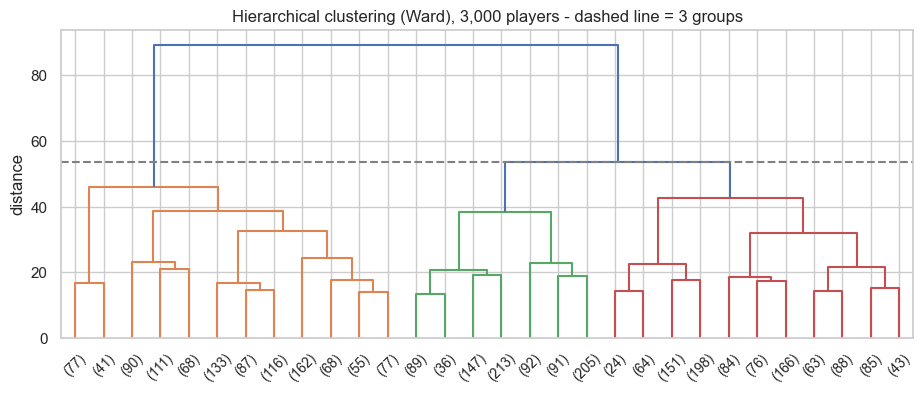

K-Means silhouette: 0.162
Ward silhouette: 0.101 | agreement with K-Means (ARI): 0.338
DBSCAN eps=1.0: groups 4 | noise share 0.382 | ARI with K-Means 0.053
col_0  0.2  0.4  0.6  0.8   1.0
row_0                          
-1       1   85  324  383   354
 0       0    0    0    0  1177
 1       0    0    0  626     0
 2       0    0   36    0     0
 3       0    0   14    0     0
all settings (from src/clustering.py):


,method,groups,largest_group_share,noise_share,silhouette,agreement_with_kmeans_ARI,same_opening_variety_in_group
0,"K-Means (k=3, fitted on all players)",3,0.3847,0.0000,0.1624,1.0000,0.5103
1,"Hierarchical, Ward (cut into 3 groups)",3,0.3617,0.0000,0.1007,0.3382,0.5443
2,"DBSCAN (eps=0.6, min_samples=14)",1,0.0127,0.9873,NaN,-0.0023,1.0000
3,"DBSCAN (eps=0.8, min_samples=14)",2,0.2177,0.7210,0.1512,0.0100,1.0000
4,"DBSCAN (eps=1.0, min_samples=14)",4,0.3923,0.3823,0.0427,0.0533,1.0000
5,"DBSCAN (eps=1.2, min_samples=14)",3,0.4640,0.2080,0.0850,0.0477,1.0000
6,"DBSCAN (eps=1.5, min_samples=14)",1,0.9357,0.0643,NaN,0.0217,0.5322


In [32]:
# hierarchical (Ward) and DBSCAN are slow on many players -> random 3,000 players, compared with K-Means on the same players
small = np.random.RandomState(RANDOM_STATE).choice(len(X25), size=min(3000, len(X25)), replace=False)
Xs = X25[small]
km_lab = style["kmeans"].predict(Xs)

Z = linkage(Xs, method="ward")
plt.figure(figsize=(11, 4))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=Z[-2, 2])
plt.axhline(Z[-2, 2], color="grey", ls="--"); plt.title("Hierarchical clustering (Ward), 3,000 players - dashed line = 3 groups")
plt.ylabel("distance"); plt.show()
hc_lab = fcluster(Z, t=3, criterion="maxclust")

db_lab = DBSCAN(eps=1.0, min_samples=14).fit_predict(Xs)
print("K-Means silhouette:", round(silhouette_score(Xs, km_lab), 3))
print("Ward silhouette:", round(silhouette_score(Xs, hc_lab), 3), "| agreement with K-Means (ARI):", round(adjusted_rand_score(km_lab, hc_lab), 3))
print("DBSCAN eps=1.0: groups", len(set(db_lab) - {-1}), "| noise share", round((db_lab == -1).mean(), 3),
      "| ARI with K-Means", round(adjusted_rand_score(km_lab, db_lab), 3))
print(pd.crosstab(db_lab, players25["opening_variety"].values[small]))
print("all settings (from src/clustering.py):")
pd.read_csv(RES + "clustering_method_comparison.csv")

notes: Ward gives a lower silhouette (0.10) and agrees only partly with K-Means (ARI 0.34).
DBSCAN does not find real style groups: either almost everyone is noise or everything is one blob, and the crosstab shows
each DBSCAN group has exactly **one** opening-variety value - opening variety only takes 5 values (0.2 ... 1.0),
so DBSCAN just separates those 5 layers. so K-Means with k=3 is the most useful, but styles form one continuous cloud.
the K-Means model + scaler are saved in `models/style_kmeans.joblib` and the app uses them.

## 19. the app
`app.py` (Streamlit). Run from the project folder: `streamlit run app.py`, then open http://localhost:8501.
Upload a .pgn file (one or many games) or paste moves. For each game it uses the latest cutoff the game reached
(10/15/20/25/30 moves), runs Stockfish on that board, and shows White win / draw / Black win chances.
Ratings come from the file or can be typed in. If Stockfish is missing it uses the models without Stockfish
(`results/fallback_models_cv.csv`: about 2-3 points lower). For players with 5+ games in the file it shows the style group.

## 20. summary and limitations
| What | Result |
|---|---|
| 2013 midterm games, before -> after (test) | 62.4% -> 66.2% (always White 51.0%) |
| 2025 final model, move 10 (untouched test, 200k games) | **58.1%**, macro-F1 0.39 (always White 49.6%) |
| decisive games only (test) | 60.8% (always White 52.0%) |
| model at least 80% sure (test, 4% of games) | right 88% of the time |
| more moves seen (train CV, move 10 -> 30) | 58.0% -> 71.9% |
| clustering (83,870 players) | 3 overlapping groups, silhouette 0.17 |

limitations:
- the model never predicts a draw (4% of games, look like normal games after 10 moves)
- 2025 data is one day of Lichess blitz; history features could not help with so little history
- training on 200,000 games (not all 600k) to save Stockfish time; the learning curve showed only ~0.3 points more from 500k
- clustering groups overlap (low silhouette); castling and captures are each measured twice (correlated features)